# Practice Notebook 1 (Week 2): Categorical Data, Chi-Square and Fisher's Exact Test

Advanced Statistics Course, Brain Science, Period 2

This notebook lets you practise the categorical-data part of Week 2. It combines **paper-and-pencil exercises** (do these by hand first, **do not use Python**) with **Python exercises**.

**How to use this notebook:** every exercise is followed by its solution. For the coding parts, first work in the cell marked `# your answer`, then compare with the solution cell(s) underneath. Try not to scroll ahead.

For the Python exercises you need *numpy*, *pandas*, *scipy* and *matplotlib*.

### Learning Goals
- Compute expected frequencies, the $\chi^2$ statistic and degrees of freedom by hand and in Python.
- Check the assumptions of the $\chi^2$ test and decide when to switch to Fisher's exact test.
- Understand the difference between scipy's default $\chi^2$ output and the textbook formula (continuity correction).
- Compute Fisher's exact p-value by enumerating tables with fixed margins.
- Interpret an association correctly: direction, size and limits (association ≠ causation).

## Part 1: Chi-Square Test by Hand

**1.1** A neuropsychology clinic assessed 150 stroke patients. For each patient the hemisphere of the lesion was recorded, together with the outcome of a standard language assessment (aphasia, mild language deficit, or no deficit).

| Lesion | Aphasia | Mild deficit | No deficit | Total |
|--------|---------|--------------|------------|-------|
| Left   | 30      | 20           | 25         | 75    |
| Right  | 15      | 20           | 40         | 75    |
| Total  | 45      | 40           | 65         | 150   |

### Tasks (paper and pencil, **do not use Python!**)
a) State $H_0$ and $H_1$.

b) Compute the table of expected frequencies.

c) Compute the $\chi^2$ statistic.

d) Determine the degrees of freedom and the critical value at $\alpha = 0.05$.

e) Make a decision and formulate the conclusion.

f) Describe the *direction* of the association using row percentages.

g) Which cells contribute most to $\chi^2$?

### Answer 1.1

**a)** $H_0$: lesion hemisphere and language outcome are independent (no association). $H_1$: they are associated.

**b)** $E_{ij} = \frac{\text{row total} \times \text{column total}}{n}$. Both rows have total 75, so both rows get the same expected counts:

- Aphasia: $E = \frac{75 \times 45}{150} = 22.5$
- Mild deficit: $E = \frac{75 \times 40}{150} = 20$
- No deficit: $E = \frac{75 \times 65}{150} = 32.5$

| Lesion | Aphasia | Mild deficit | No deficit |
|--------|---------|--------------|------------|
| Left   | 22.5    | 20           | 32.5       |
| Right  | 22.5    | 20           | 32.5       |

**c)** $\chi^2 = \sum \frac{(O-E)^2}{E}$

| Cell | $(O-E)^2/E$ |
|------|-------------|
| Left–Aphasia | $(30-22.5)^2/22.5 = 56.25/22.5 = 2.500$ |
| Left–Mild | $(20-20)^2/20 = 0$ |
| Left–None | $(25-32.5)^2/32.5 = 56.25/32.5 = 1.731$ |
| Right–Aphasia | $(15-22.5)^2/22.5 = 2.500$ |
| Right–Mild | $0$ |
| Right–None | $(40-32.5)^2/32.5 = 1.731$ |

$\chi^2 = 2.500 + 0 + 1.731 + 2.500 + 0 + 1.731 = 8.46$

**d)** $df = (r-1)(c-1) = (2-1)(3-1) = 2$. Critical value at $\alpha = 0.05$: **5.99**.

**e)** $8.46 > 5.99$, so we **reject $H_0$**. Lesion hemisphere and language outcome are significantly associated ($p < .05$).

**f)** Aphasia: $30/75 = 40\%$ of left-lesion patients vs. $15/75 = 20\%$ of right-lesion patients. No deficit: $25/75 = 33\%$ (left) vs. $40/75 = 53\%$ (right). Left-hemisphere lesions go together with more aphasia and fewer intact outcomes, which fits left-lateralised language.

**g)** The aphasia cells (2.50 each) contribute most, then the no-deficit cells (1.73 each). The mild-deficit column contributes nothing, because observed = expected.

**1.2 Assumption check** (paper and pencil)

For each scenario decide whether the $\chi^2$ test of independence is appropriate. If not, say what is violated and what you would do instead.

**(i)** Pilot study, 24 participants: sleep deprivation (yes/no) × false memory (yes/no).

|                 | False memory | No false memory | Total |
|-----------------|--------------|-----------------|-------|
| Sleep-deprived  | 10           | 2               | 12    |
| Rested          | 5            | 7               | 12    |
| Total           | 15           | 9               | 24    |

**(ii)** A 3 × 4 table (n = 180). The expected frequencies of its 12 cells are: 21.0, 14.2, 18.6, 4.2, 16.8, 11.4, 14.9, 3.8, 22.3, 15.1, 19.7, 18.0.

**(iii)** 40 participants (20 patients, 20 controls) each classify 5 emotional faces. The researcher enters all 200 classifications (correct/incorrect) into a 2 × 2 table Group × Response and runs a $\chi^2$ test.

**(iv)** A 3 × 3 table in which one expected frequency is 0.8 and all others exceed 5.

### Answer 1.2

**(i)** Expected counts: $12 \times 15/24 = 7.5$ and $12 \times 9/24 = 4.5$ in each row. Two cells have $E = 4.5 < 5$. In a 2 × 2 table every expected count should be > 5, so the $\chi^2$ approximation is unreliable. **Use Fisher's exact test.**

**(ii)** Two of 12 cells (4.2 and 3.8) are ≤ 5, i.e. $2/12 = 16.7\% \le 20\%$, and no cell is ≤ 1. **The $\chi^2$ test is acceptable** under the rule for larger tables.

**(iii)** **Independence of observations is violated.** Each participant contributes 5 counts, possibly to different cells, so the 200 counts are not independent. Fix: give one outcome per participant (for example "≥ 3 of 5 correct" vs. "< 3 correct"), giving a 2 × 2 table with n = 40, or use a method for repeated measures.

**(iv)** One cell has $E \le 1$, which breaks the "none ≤ 1" rule. **Use Fisher's exact test** (it generalises to larger tables but is computationally heavier). Merging sparse categories, if that makes sense for the content, is another option.

## Part 2: Chi-Square Test in Python

**1.3** In the lecture, 200 cats were trained to dance with either food or affection as a reward:

|              | Food | Affection | Total |
|--------------|------|-----------|-------|
| Dance: Yes   | 28   | 48        | 76    |
| Dance: No    | 10   | 114       | 124   |
| Total        | 38   | 162       | 200   |

The lecture reports $\chi^2 \approx 25.35$, $df = 1$.

Tasks:
1. Compute the expected frequencies **without** `chi2_contingency`. Hint: `np.outer(row_totals, col_totals) / n`.
2. Compute $\chi^2$ and $df$ yourself, and obtain the p-value with `stats.chi2.sf`.
3. Reproduce the critical values for $df = 1, 2, 3$ at $\alpha = 0.05$ using `stats.chi2.ppf`.
4. Now run `stats.chi2_contingency(table)` with default settings. Do you get the same $\chi^2$? If not, find out why and make scipy reproduce the lecture value.

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats

cats = np.array([[28, 48],
                 [10, 114]])

# 1. Expected frequencies
# your answer

# 2. Chi-square statistic, df and p-value
# your answer

# 3. Critical values for df = 1, 2, 3
# your answer

# 4. Compare with stats.chi2_contingency
# your answer

### Solution 1.3

In [2]:
import numpy as np
import pandas as pd
import scipy.stats as stats

cats = np.array([[28, 48],
                 [10, 114]])

# 1. Expected frequencies
row_totals = cats.sum(axis=1)
col_totals = cats.sum(axis=0)
n = cats.sum()
expected = np.outer(row_totals, col_totals) / n
print("Expected frequencies:")
print(pd.DataFrame(expected, index=["Dance: Yes", "Dance: No"], columns=["Food", "Affection"]).round(2))

# 2. Chi-square, df, p-value
chi2_manual = ((cats - expected) ** 2 / expected).sum()
dof = (cats.shape[0] - 1) * (cats.shape[1] - 1)
p_manual = stats.chi2.sf(chi2_manual, dof)   # sf = 1 - cdf = right-tail probability
print(f"\nManual: chi2 = {chi2_manual:.2f}, df = {dof}, p = {p_manual:.2e}")

# 3. Critical values
for d in [1, 2, 3]:
    print(f"Critical value (alpha = .05, df = {d}): {stats.chi2.ppf(0.95, d):.2f}")

Expected frequencies:
             Food  Affection
Dance: Yes  14.44      61.56
Dance: No   23.56     100.44

Manual: chi2 = 25.36, df = 1, p = 4.77e-07
Critical value (alpha = .05, df = 1): 3.84
Critical value (alpha = .05, df = 2): 5.99
Critical value (alpha = .05, df = 3): 7.81


In [3]:
# 4. scipy default vs. textbook formula
chi2_default, p_default, _, _ = stats.chi2_contingency(cats)
chi2_nocorr, p_nocorr, _, _ = stats.chi2_contingency(cats, correction=False)

print(f"chi2_contingency (default):          chi2 = {chi2_default:.2f}, p = {p_default:.2e}")
print(f"chi2_contingency (correction=False): chi2 = {chi2_nocorr:.2f}, p = {p_nocorr:.2e}")

chi2_contingency (default):          chi2 = 23.52, p = 1.24e-06
chi2_contingency (correction=False): chi2 = 25.36, p = 4.77e-07


**Why the difference?** For tables with $df = 1$ (2 × 2), `chi2_contingency` applies **Yates' continuity correction** by default: it shrinks every $|O - E|$ by 0.5 before squaring. This makes the test slightly more conservative (smaller $\chi^2$, larger p). The lecture formula $\sum (O-E)^2/E$ has no correction, so `correction=False` reproduces the lecture value (25.356, reported as 25.35). For larger tables ($df > 1$) scipy never applies the correction. Either way the conclusion here is the same: training type and dancing are strongly associated.

*Side note:* the exact critical value for $df = 3$ is 7.815. The lecture rounds it up to 7.82, scipy prints 7.81.

**1.4** Check your hand calculation from **1.1** in Python.

1. Run the $\chi^2$ test on the stroke table and compare $\chi^2$, $df$ and $p$ with your paper results.
2. Compute the contribution $(O-E)^2/E$ of each cell and display it as a table.
3. Plot the **row percentages** as a 100 % stacked bar chart (one bar per lesion side). Why are row percentages more informative here than raw counts?

In [ ]:
import matplotlib.pyplot as plt

stroke = pd.DataFrame([[30, 20, 25],
                       [15, 20, 40]],
                      index=["Left", "Right"],
                      columns=["Aphasia", "Mild deficit", "No deficit"])

# 1. Chi-square test
# your answer

# 2. Cell contributions
# your answer

# 3. Row percentages + 100 % stacked bar chart
# your answer

### Solution 1.4

chi2 = 8.46, df = 2, p = 0.0145

Contribution of each cell to chi2:
       Aphasia  Mild deficit  No deficit
Left       2.5           0.0       1.731
Right      2.5           0.0       1.731

Row percentages:
       Aphasia  Mild deficit  No deficit
Left      40.0          26.7        33.3
Right     20.0          26.7        53.3


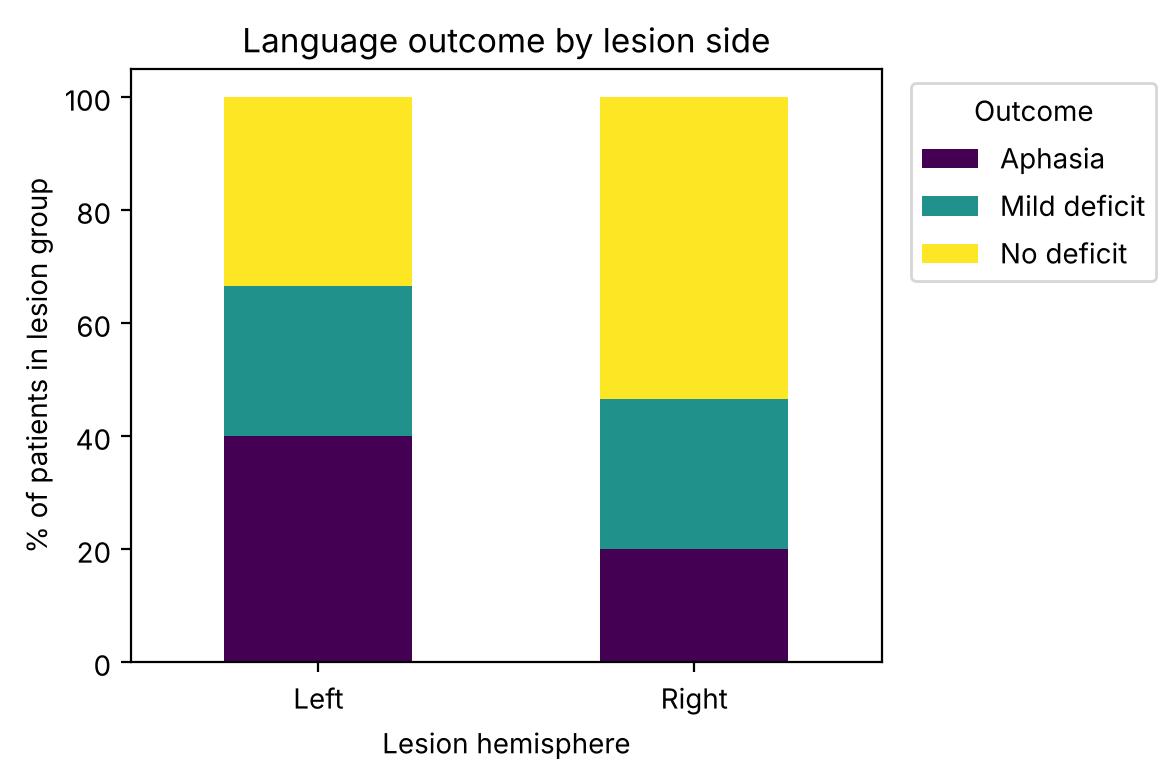

In [5]:
import matplotlib.pyplot as plt

stroke = pd.DataFrame([[30, 20, 25],
                       [15, 20, 40]],
                      index=["Left", "Right"],
                      columns=["Aphasia", "Mild deficit", "No deficit"])

# 1. Chi-square test (df = 2, so no continuity correction is applied)
chi2, p, dof, expected = stats.chi2_contingency(stroke)
print(f"chi2 = {chi2:.2f}, df = {dof}, p = {p:.4f}")

# 2. Cell contributions
contrib = (stroke - expected) ** 2 / expected
print("\nContribution of each cell to chi2:")
print(contrib.round(3))

# 3. Row percentages
row_pct = stroke.div(stroke.sum(axis=1), axis=0) * 100
print("\nRow percentages:")
print(row_pct.round(1))

row_pct.plot(kind="bar", stacked=True, figsize=(6, 4), colormap="viridis")
plt.ylabel("% of patients in lesion group")
plt.xlabel("Lesion hemisphere")
plt.title("Language outcome by lesion side")
plt.legend(title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The results match the paper solution: $\chi^2 = 8.46$, $df = 2$, $p \approx .015$. Row percentages put both lesion groups on the same scale (here both groups have 75 patients, but usually group sizes differ). The $\chi^2$ test only says *that* an association exists. Row percentages and cell contributions show *where* and in *which direction*.

## Part 3: Fisher's Exact Test

**1.5** A patient with **blindsight** (damage to primary visual cortex, V1) reports seeing nothing in the left visual field. In 10 trials, a stimulus is flashed in the blind field in exactly 5 trials; the patient knows this and has to guess the 5 "stimulus" trials. The patient picks 4 of the 5 stimulus trials correctly.

### Tasks (paper and pencil, **do not use Python!**)
a) Write down the 2 × 2 table (Truth: stimulus/no stimulus × Response: "stimulus"/"no stimulus") with all margins.

b) State $H_0$.

c) Let $T$ = number of correctly identified stimulus trials. Compute $P(T = 4)$ and $P(T = 5)$ under $H_0$ using $P(a) = \binom{a+b}{a}\binom{c+d}{c} / \binom{n}{a+c}$.

d) Compute the one-tailed p-value and make a decision at $\alpha = 0.05$.

e) Why is a one-tailed p-value appropriate here?

f) Would 5 of 5 correct have been significant?

g) Design question: in a version with only **6 trials** (3 with stimulus), could *any* result be significant at $\alpha = 0.05$?

### Answer 1.5

**a)**

|                  | Response "stimulus" | Response "no stimulus" | Total |
|------------------|---------------------|------------------------|-------|
| Stimulus         | 4 (a)               | 1 (b)                  | 5     |
| No stimulus      | 1 (c)               | 4 (d)                  | 5     |
| Total            | 5                   | 5                      | 10    |

All margins are fixed by the design (5 stimulus trials, patient must choose 5).

**b)** $H_0$: the patient guesses at random (response is independent of the stimulus).

**c)** $\binom{10}{5} = 252$.
- $P(T=4) = \binom{5}{4}\binom{5}{1}/252 = 5 \cdot 5/252 = 25/252 = 0.0992$
- $P(T=5) = \binom{5}{5}\binom{5}{0}/252 = 1/252 = 0.0040$

**d)** $p = P(T \ge 4) = 26/252 = 0.103 > 0.05$, so we **fail to reject $H_0$**. There is not enough evidence that the patient detects stimuli in the blind field above chance.

**e)** Only *better-than-chance* performance supports the research hypothesis (residual processing of blind-field stimuli). Performing worse than chance would not count as evidence for it, so only the upper tail is relevant.

**f)** Yes: $p = 1/252 = 0.004 < 0.05$.

**g)** No. With 6 trials there are $\binom{6}{3} = 20$ possible choices. Even a perfect result has $p = 1/20 = 0.05$, which is not $< 0.05$. A design that is too small can never produce significance, however good the patient is.

**1.6** Implement Fisher's exact test yourself.

1. Write a function `table_prob(a, b, c, d)` that returns the probability of a 2 × 2 table with the **factorial formula** $P = \frac{(a+b)!\,(c+d)!\,(a+c)!\,(b+d)!}{a!\,b!\,c!\,d!\,n!}$. Use `math.factorial`.
2. Enumerate **all** tables that have the same margins as the blindsight table (vary $a$; $b$, $c$, $d$ follow from the margins). Print each table's probability and check that they sum to 1.
3. Compute the one-tailed p-value and compare it with `stats.fisher_exact(table, alternative="greater")`.
4. Plot the null distribution of $a$ as a bar chart and highlight the bars that make up the p-value.

In [ ]:
import math

blindsight = np.array([[4, 1],
                       [1, 4]])

# 1. table_prob(a, b, c, d)
# your answer

# 2. Enumerate all tables with the same margins
# your answer

# 3. One-tailed p-value, compare with stats.fisher_exact
# your answer

# 4. Bar plot of the null distribution
# your answer

### Solution 1.6

In [7]:
import math

blindsight = np.array([[4, 1],
                       [1, 4]])

# 1. Probability of one 2x2 table with fixed margins
def table_prob(a, b, c, d):
    n = a + b + c + d
    num = (math.factorial(a + b) * math.factorial(c + d) *
           math.factorial(a + c) * math.factorial(b + d))
    den = (math.factorial(a) * math.factorial(b) * math.factorial(c) *
           math.factorial(d) * math.factorial(n))
    return num / den

# 2. Enumerate all tables with the observed margins
(a_obs, b_obs), (c_obs, d_obs) = blindsight
r1, r2 = a_obs + b_obs, c_obs + d_obs
c1 = a_obs + c_obs
n = r1 + r2

a_values = range(max(0, c1 - r2), min(r1, c1) + 1)
probs = {}
for a in a_values:
    b, c = r1 - a, c1 - a
    d = r2 - c
    probs[a] = table_prob(a, b, c, d)
    print(f"a = {a}: table [[{a}, {b}], [{c}, {d}]]  P = {probs[a]:.4f}")
print(f"Sum of probabilities: {sum(probs.values()):.4f}")

# 3. One-tailed p-value: observed table + all tables MORE extreme in the expected direction
p_one = sum(p for a, p in probs.items() if a >= a_obs)
_, p_scipy = stats.fisher_exact(blindsight, alternative="greater")
print(f"\nOne-tailed p (by hand): {p_one:.4f}")
print(f"One-tailed p (scipy):   {p_scipy:.4f}")

a = 0: table [[0, 5], [5, 0]]  P = 0.0040
a = 1: table [[1, 4], [4, 1]]  P = 0.0992
a = 2: table [[2, 3], [3, 2]]  P = 0.3968
a = 3: table [[3, 2], [2, 3]]  P = 0.3968
a = 4: table [[4, 1], [1, 4]]  P = 0.0992
a = 5: table [[5, 0], [0, 5]]  P = 0.0040
Sum of probabilities: 1.0000

One-tailed p (by hand): 0.1032
One-tailed p (scipy):   0.1032


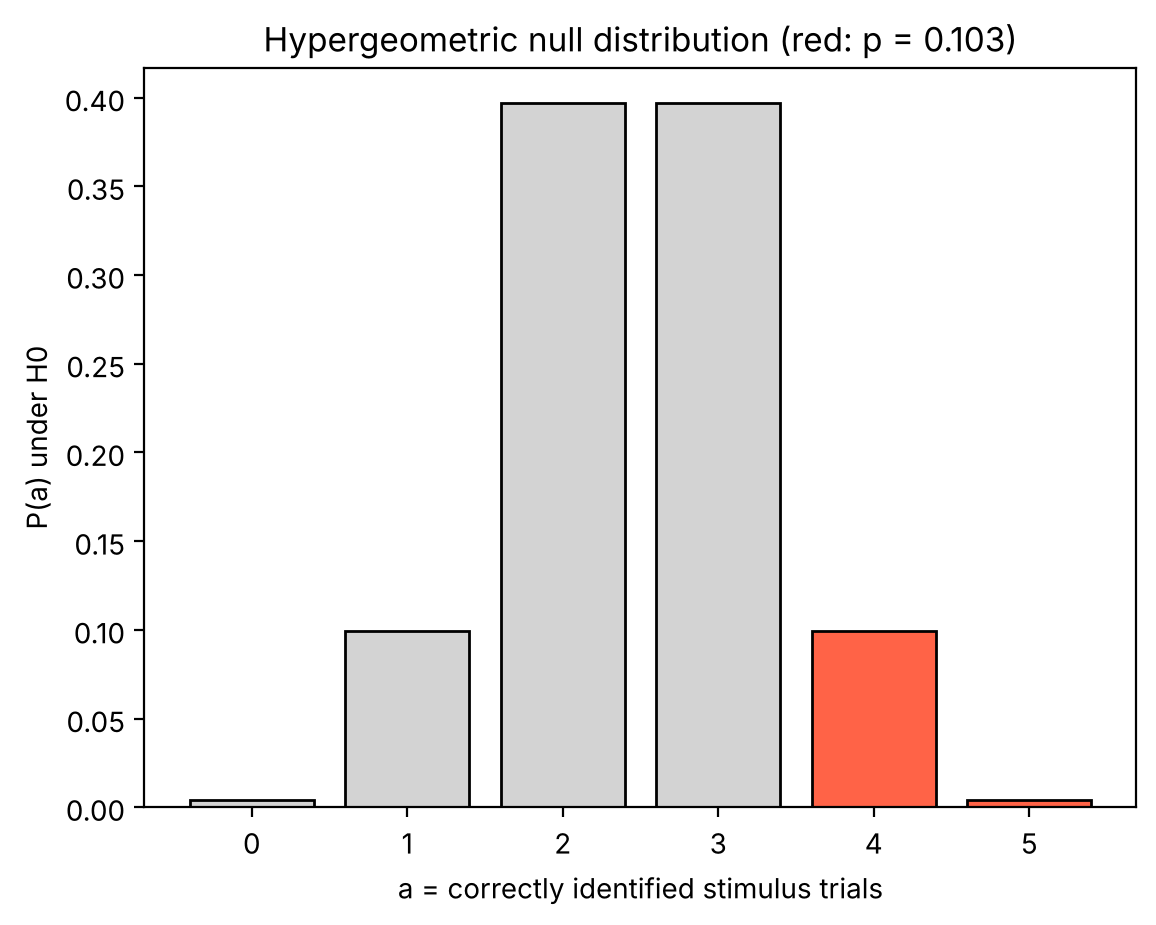

In [8]:
# 4. Null distribution
colors = ["tomato" if a >= a_obs else "lightgrey" for a in probs]
plt.bar(list(probs.keys()), list(probs.values()), color=colors, edgecolor="black")
plt.xlabel("a = correctly identified stimulus trials")
plt.ylabel("P(a) under H0")
plt.title(f"Hypergeometric null distribution (red: p = {p_one:.3f})")
plt.show()

The null distribution of $a$ is **hypergeometric** (sampling 5 trials without replacement from 5 stimulus + 5 non-stimulus trials), which is why `stats.hypergeom` gives the same answer. Note how **discrete** the distribution is: there are only 6 possible outcomes, so only a handful of p-values can occur at all.

**1.7** Write a function `analyse_table(table)` that

1. computes the expected frequencies,
2. uses Fisher's exact test (two-sided) if the table is 2 × 2 and any expected frequency is < 5, and otherwise the $\chi^2$ test (use `correction=False` to match the lecture formula),
3. prints which test was used, why, and the p-value.

Apply it to the sleep-deprivation table from **1.2 (i)** and to the stroke table from **1.1**.

In [ ]:
sleep = np.array([[10, 2],
                  [5, 7]])

def analyse_table(table):
    # your answer
    pass

# analyse_table(sleep)
# analyse_table(stroke.values)

### Solution 1.7

In [10]:
sleep = np.array([[10, 2],
                  [5, 7]])

def analyse_table(table, alpha=0.05):
    table = np.asarray(table)
    chi2, p_chi2, dof, expected = stats.chi2_contingency(table, correction=False)
    print("Expected frequencies:\n", expected.round(2))
    if table.shape == (2, 2) and (expected < 5).any():
        _, p = stats.fisher_exact(table)
        print("2x2 table with expected count(s) < 5  ->  Fisher's exact test")
    else:
        p = p_chi2
        print(f"Expected counts adequate  ->  chi-square test (chi2 = {chi2:.2f}, df = {dof})")
    decision = "reject H0" if p < alpha else "fail to reject H0"
    print(f"p = {p:.4f}  ->  {decision}\n")
    return p

analyse_table(sleep)
analyse_table(stroke.values)

Expected frequencies:
 [[7.5 4.5]
 [7.5 4.5]]
2x2 table with expected count(s) < 5  ->  Fisher's exact test
p = 0.0894  ->  fail to reject H0

Expected frequencies:
 [[22.5 20.  32.5]
 [22.5 20.  32.5]]
Expected counts adequate  ->  chi-square test (chi2 = 8.46, df = 2)
p = 0.0145  ->  reject H0



np.float64(0.014541200706177662)

For the sleep table, Fisher's exact test gives $p \approx .09$, so the pilot does not show a significant association despite 83 % vs. 42 % false memories: with n = 24 the evidence is still weak. For the stroke table the expected counts are fine, so the $\chi^2$ test is used ($p \approx .015$).

### Optional Challenge: Complete this exercise if you've wrapped up the rest and have some extra time!

**1.8 Why does the $\chi^2$ approximation fail in small samples?**

Simulate 5,000 data sets of **n = 20** participants under $H_0$ (two *independent* binary variables, with $P(\text{row 1}) = 0.5$ and $P(\text{column 1}) = 0.25$). For each data set, build the 2 × 2 table and compute the p-value with (a) the uncorrected $\chi^2$ test, (b) the Yates-corrected $\chi^2$ test and (c) Fisher's exact test (two-sided). Skip tables with an empty row or column.

Because $H_0$ is true, a good test should reject in about 5 % of data sets. Estimate the **Type I error rate** of each test, and the percentage of data sets in which the uncorrected $\chi^2$ test and Fisher's test reach **different decisions**. Then repeat with n = 200.

In [ ]:
rng = np.random.default_rng(1)

def simulate_type1(n, n_sim=5000, p_row=0.5, p_col=0.25, alpha=0.05):
    # your answer
    pass

# simulate_type1(20)
# simulate_type1(200)

### Solution 1.8

In [12]:
rng = np.random.default_rng(1)

def simulate_type1(n, n_sim=5000, p_row=0.5, p_col=0.25, alpha=0.05):
    rejections = {"chi2 (no correction)": 0, "chi2 (Yates)": 0, "Fisher": 0}
    valid, disagree = 0, 0
    for _ in range(n_sim):
        rows = rng.random(n) < p_row          # variable 1
        cols = rng.random(n) < p_col          # variable 2, independent of variable 1
        table = np.array([[np.sum(rows & cols),  np.sum(rows & ~cols)],
                          [np.sum(~rows & cols), np.sum(~rows & ~cols)]])
        if (table.sum(axis=0) == 0).any() or (table.sum(axis=1) == 0).any():
            continue
        valid += 1
        rej_chi2 = stats.chi2_contingency(table, correction=False)[1] < alpha
        rej_fisher = stats.fisher_exact(table)[1] < alpha
        rejections["chi2 (no correction)"] += rej_chi2
        rejections["chi2 (Yates)"] += stats.chi2_contingency(table, correction=True)[1] < alpha
        rejections["Fisher"] += rej_fisher
        disagree += rej_chi2 != rej_fisher
    print(f"n = {n} ({valid} valid tables)")
    for name, r in rejections.items():
        print(f"  {name:22s} Type I error rate = {r / valid:.3f}")
    print(f"  chi2 and Fisher reach different decisions in {100 * disagree / valid:.1f}% of data sets")

simulate_type1(20)
simulate_type1(200)

n = 20 (4984 valid tables)
  chi2 (no correction)   Type I error rate = 0.046
  chi2 (Yates)           Type I error rate = 0.007
  Fisher                 Type I error rate = 0.019
  chi2 and Fisher reach different decisions in 2.7% of data sets


n = 200 (5000 valid tables)
  chi2 (no correction)   Type I error rate = 0.053
  chi2 (Yates)           Type I error rate = 0.035
  Fisher                 Type I error rate = 0.042
  chi2 and Fisher reach different decisions in 1.1% of data sets


With n = 20 the rejection rates differ a lot: the Yates-corrected $\chi^2$ test and Fisher's exact test reject far less often than 5 % (they are **conservative**, because a small table can only produce a few discrete p-values), while the uncorrected $\chi^2$ test lands near 5 % on average. The decision for a particular sparse table therefore depends on which test you choose. With n = 200 all three rates move towards 5 %.

The lecture's point is about **reliability**: the $\chi^2$ p-value comes from an approximate distribution, and for small expected counts this approximation can be too small or too large for a particular table. Fisher's p-value is computed exactly, so its Type I error rate is guaranteed never to exceed $\alpha$. The price is lower power when the sample is small.

## Conceptual Questions

1. In **1.1** the association was significant. Can you conclude that left-hemisphere lesions *cause* aphasia? Name two alternative explanations.
2. The $\chi^2$ statistic is always positive. What does it *not* tell you, and what should you report in addition?
3. Imagine every cell in the stroke table were **doubled** (n = 300, same proportions). What would happen to $\chi^2$ and the p-value? What does this imply for interpreting a significant $\chi^2$?
4. Fisher's test is called "exact". Exact with respect to what? Does that make it always the better choice?
5. In **1.5**, the patient performed at 80 % correct, yet the result was not significant. What would you advise the researcher?

### Answers

1. **No.** $\chi^2$ shows an association in observational data, not causation. Alternative explanations include confounders such as lesion **size** or **location within the hemisphere**, stroke type, age, or referral bias (clinics may see more left-lesion patients *because* they have language problems).

2. $\chi^2$ is non-directional and depends on sample size. It does not tell you **which cells** drive the association, the **direction**, or **how strong** it is. Report row or column percentages (and cell contributions), ideally an effect size, together with $\chi^2(df) = \ldots$, $p = \ldots$.

3. Each $(O-E)^2/E$ term doubles ($O$ and $E$ both double, so the numerator quadruples and the denominator doubles), so $\chi^2 = 16.92$ and $p$ becomes much smaller, even though the **proportions are identical**. Significance therefore depends on $n$: with very large samples even trivial associations become significant. Always look at the size of the effect, not only at $p$.

4. It is exact in the sense that the p-value is computed from the **exact (hypergeometric) probability distribution of tables under $H_0$, given fixed margins**, instead of the approximate $\chi^2$ distribution. It is not always better: it is conservative because of discreteness, it becomes computationally heavy for large tables, and with large samples $\chi^2$ gives practically the same answer.

5. The design has very low power: with 10 trials only 26/252 or 1/252 outcomes are possible in the upper tail. Increase the number of trials (or repeat sessions) so that a true above-chance ability can reach significance. A non-significant result here does **not** show that the patient is guessing.